# AR order scale-selection pipeline with selectable weights and GUDHI

This notebook implements the pipeline from Thesis Section 3.4: simulate an AR($p$) process, split it into training and test data, learn the least-squares completion $\widehat A_k$, lift every window to $\mathbb R^{k_{\max}}$, build a GUDHI flag complex, assemble the scale-similarity matrix, and select $k^*$ from its principal eigenvector.

Two graph weights are available. The first is the observed $L^1$ distance

$$
w_k^{L^1}(s,t)=\left\|p_s^{(k)}-p_t^{(k)}\right\|_1.
$$

The second is a plug-in covariance dissimilarity. It estimates the autocovariance from the training data and incorporates the fitted completion matrix $\widehat A_k$. Both weights follow the edge convention $w_k(s,t)\leq\tau$.

All simplex-tree functionals are imported from `001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py`; the remaining reusable code is imported from `00_FUNCTIONS.py`.

## 1. Load the implementation

Simplicial-complex functionals are imported explicitly from `001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py`. The remaining reusable pipeline code is imported from `00_FUNCTIONS.py`.

In [ ]:
from pathlib import Path
import importlib.util
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate both companion modules whether the notebook server starts in Code/
# or in the repository root.
_search_directories = [
    Path.cwd(),
    Path.cwd() / "Code",
    Path.cwd() / "Code" / "Code_AR_processes",
    Path.cwd() / "Code_AR_processes",
    Path.cwd().parent,
    Path.cwd().parent / "Code",
    Path.cwd().parent / "Code_AR_processes",
]
FUNCTIONALS_PATH = next(
    (directory / "001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py"
     for directory in _search_directories
     if (directory / "001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py").exists()),
    None,
)
FUNCTIONS_PATH = next(
    (directory / "00_FUNCTIONS.py"
     for directory in _search_directories
     if (directory / "00_FUNCTIONS.py").exists()),
    None,
)
if FUNCTIONALS_PATH is None or FUNCTIONS_PATH is None:
    raise FileNotFoundError(
        "Could not find 001_SIMPLICIAL_COMPLEX_FUNCTIONALS.py and 00_FUNCTIONS.py. "
        "Run from the repository root, Code/, or Code/Code_AR_processes/."
    )

# Explicitly import the canonical simplex-tree functionals first.
_functionals_spec = importlib.util.spec_from_file_location(
    "simplicial_complex_functionals",
    FUNCTIONALS_PATH,
)
simplicial_functionals = importlib.util.module_from_spec(_functionals_spec)
sys.modules[_functionals_spec.name] = simplicial_functionals
_functionals_spec.loader.exec_module(simplicial_functionals)

FUNCTIONAL_NAMES = (
    "simplex_count",
    "vertex_count",
    "edge_count",
    "triangle_count",
    "betti_number",
    "beta_0",
    "beta_1",
    "point_complexity",
    "log_component_edge_functional",
    "functional_value",
)
globals().update({
    name: getattr(simplicial_functionals, name)
    for name in FUNCTIONAL_NAMES
})

# Import the rest of the AR scale-selection implementation.
_functions_spec = importlib.util.spec_from_file_location(
    "ar_scale_functions",
    FUNCTIONS_PATH,
)
functions = importlib.util.module_from_spec(_functions_spec)
sys.modules[_functions_spec.name] = functions
_functions_spec.loader.exec_module(functions)
globals().update({name: getattr(functions, name) for name in functions.__all__})

# Both layers must use this exact canonical module instance.
assert functions.simplicial_functionals is simplicial_functionals

plt.style.use("seaborn-v0_8-whitegrid")
print(f"Imported {len(FUNCTIONAL_NAMES)} functionals from {FUNCTIONALS_PATH}")
print(f"Imported {len(functions.__all__)} pipeline definitions from {FUNCTIONS_PATH}")

## 2. Controls

Edit the six values below. Choose `"l1"` or `"covariance"` for `weight_type`. The manually chosen $\tau$ is used at every scale. Covariance weights lie in $[0,1]$, so choose a covariance threshold in that range. The default is $\widetilde\delta=0$, and stable, nonzero AR coefficients are generated automatically from the selected order $p$.

In [10]:
# ========================= USER CONTROLS =========================
p = 1
k_max = 5
weight_type = "l1"  # choose "l1" or "covariance"
tau = 2.0            # for covariance weights, use a value in (0, 1]
alpha = 1.0
xi = 1.0
# ================================================================

CONFIG = PipelineConfig(
    p=p,
    k_max=k_max,
    weight_type=weight_type,
    tau=tau,
    alpha=alpha,
    xi=xi,
)
CONFIG

PipelineConfig(p=1, k_max=5, n_observations=500, train_fraction=0.6, burn_in=500, innovation_sd=1.0, seed=20260707, pacf_first=0.75, pacf_decay=-0.5, weight_type='l1', tau=2.0, max_simplex_dimension=2, alpha=1.0, xi=1.0, tilde_delta=0.0, similarity_mode='union')

## 3. Run the selected AR($p$) model

The next cell prints the automatically generated coefficients and displays the scale-similarity matrix as a labeled pandas table.

In [3]:
result = run_pipeline(CONFIG.p, CONFIG)
ks = np.arange(1, CONFIG.k_max + 1)

print(f"AR({CONFIG.p}) coefficients: {np.round(result['phi'], 5)}")
print(f"Weight type: {CONFIG.weight_type}")
print(f"Common threshold tau: {result['tau']:.5f}")
print(f"Selected scale k*: {result['k_star']}")

AR(1) coefficients: [0.75]
Weight type: l1
Common threshold tau: 2.00000
Selected scale k*: 4


### Functional and principal-eigenvector plots

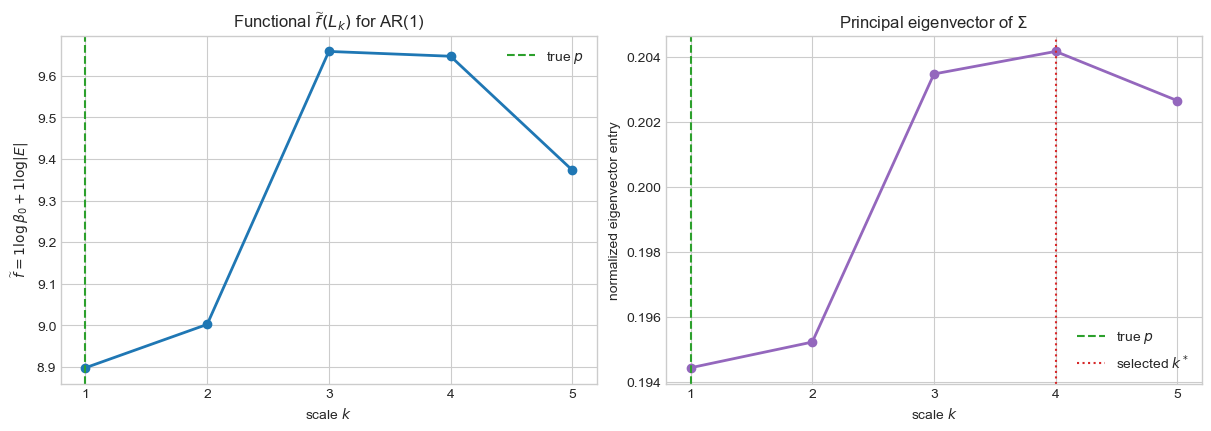

In [4]:
functional_values = np.array([result["functionals"][k] for k in ks])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

axes[0].plot(ks, functional_values, marker="o", linewidth=2, color="tab:blue")
axes[0].axvline(CONFIG.p, color="tab:green", linestyle="--", label="true $p$")
axes[0].set(
    title=rf"Functional $\widetilde f(L_k)$ for AR({CONFIG.p})",
    xlabel="scale $k$", ylabel=rf"$\widetilde f= {CONFIG.alpha:g}\log\beta_0 + {CONFIG.xi:g}\log|E|$", xticks=ks,
)
axes[0].legend()

axes[1].plot(ks, result["eigenvector"], marker="o", linewidth=2, color="tab:purple")
axes[1].axvline(CONFIG.p, color="tab:green", linestyle="--", label="true $p$")
axes[1].axvline(result["k_star"], color="tab:red", linestyle=":", label="selected $k^*$")
axes[1].set(
    title=r"Principal eigenvector of $\Sigma$",
    xlabel="scale $k$", ylabel="normalized eigenvector entry", xticks=ks,
)
axes[1].legend()

plt.show()

### Scale-similarity matrix

In [5]:
similarity_df = pd.DataFrame(
    result["sigma"],
    index=pd.Index(ks, name="k_i"),
    columns=pd.Index(ks, name="k_j"),
)
display(
    similarity_df.style
    .format(precision=4)
    .background_gradient(cmap="Blues")
    .set_caption(r"Scale-similarity matrix $\Sigma_{k_{\max}}$")
)

k_j,1,2,3,4,5
k_i,,,,,
1,8.8984,9.1180,8.9784,8.9178,8.9046
2,9.1180,9.0026,8.8406,9.0346,9.0060
3,8.9784,8.8406,9.6586,9.7071,9.6755
4,8.9178,9.0346,9.7071,9.6470,9.7165
5,8.9046,9.0060,9.6755,9.7165,9.3735


### Histograms of the selected weights

Each vertical panel uses only pairs $s<t$, so every unordered pair appears exactly once. Common bin edges make the distributions comparable across scales; the dashed line is the manually chosen threshold $\tau$.

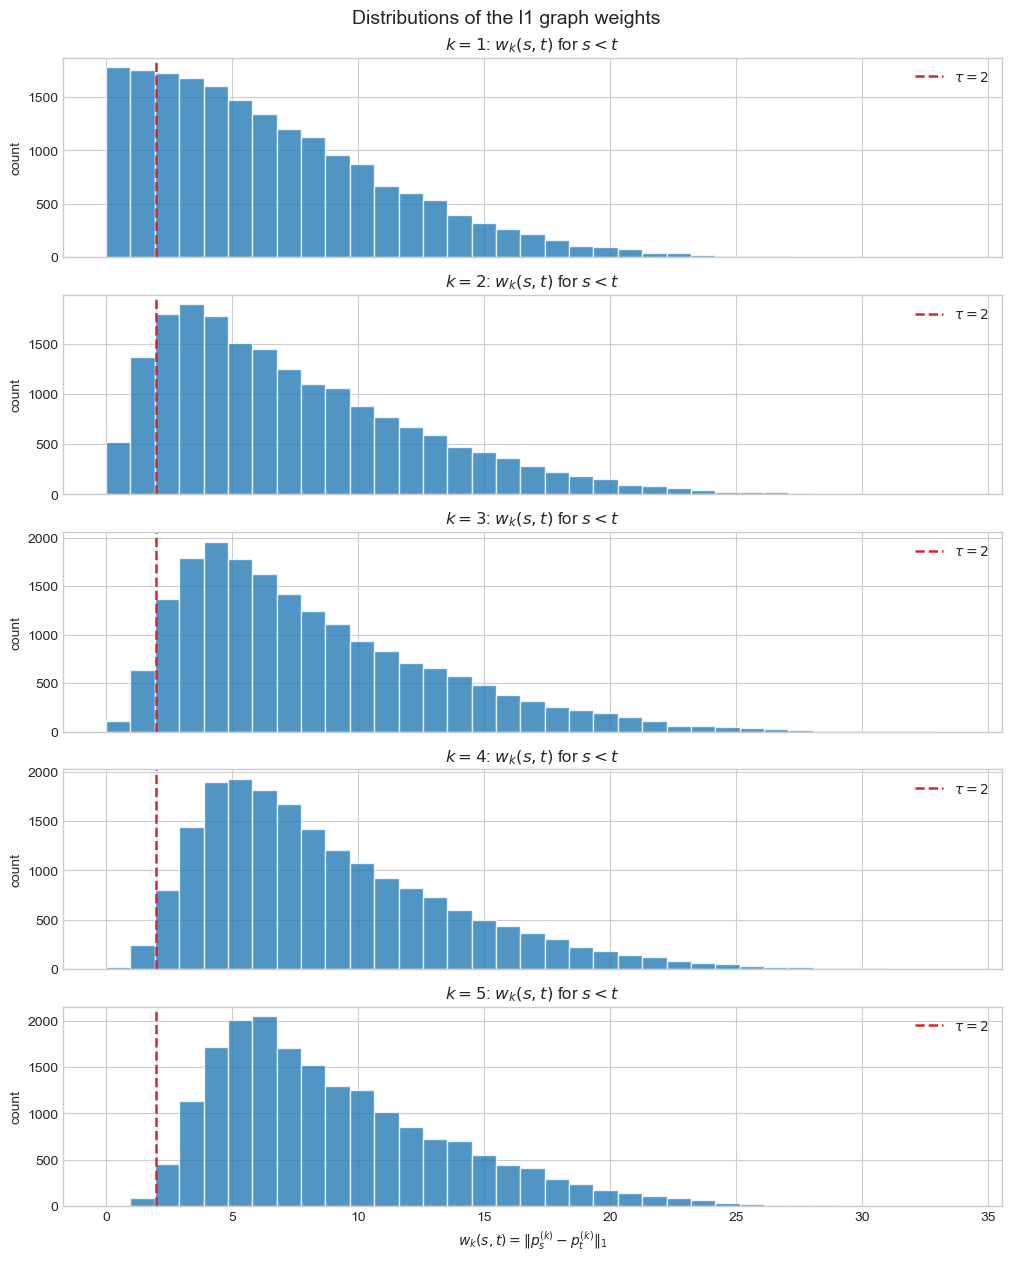

In [6]:
upper_triangle_weights = {
    k: matrix[np.triu_indices_from(matrix, k=1)]
    for k, matrix in result["weights"].items()
}
pooled_weights = np.concatenate(list(upper_triangle_weights.values()))
common_bins = np.histogram_bin_edges(pooled_weights, bins=35)

fig, axes = plt.subplots(
    CONFIG.k_max,
    1,
    figsize=(10, 2.5 * CONFIG.k_max),
    sharex=True,
    constrained_layout=True,
)
axes = np.atleast_1d(axes)

for axis, k in zip(axes, ks):
    weights = upper_triangle_weights[k]
    axis.hist(weights, bins=common_bins, color="tab:blue", alpha=0.78, edgecolor="white")
    axis.axvline(CONFIG.tau, color="tab:red", linestyle="--", linewidth=1.8, label=rf"$\tau={CONFIG.tau:g}$")
    axis.set_title(rf"$k={k}$: $w_k(s,t)$ for $s<t$")
    axis.set_ylabel("count")
    axis.legend(loc="upper right")

axes[-1].set_xlabel(weight_axis_label(CONFIG.weight_type))
fig.suptitle(f"Distributions of the {CONFIG.weight_type} graph weights", fontsize=14)
plt.show()

## 4. Re-running with another order

Change the five values in the control cell and run from that cell downward. The current result is one realization, not evidence of order-recovery performance; a later Monte Carlo layer should measure how often $k^*=p$ over independent seeds.

## 5. Experiment 1: scan $\tau$ for one AR(1) process

A single AR(1) path is simulated and held fixed throughout the experiment. For the L1 option, we vary

$$
\tau\in\{0.5,1.0,\ldots,10.0\}.
$$

Because the normalized covariance dissimilarity lies in $[0,1]$, the covariance option instead uses

$$
\tau\in\{0.05,0.10,\ldots,1.00\}.
$$

The selected $k_{\max}$, $\alpha$, $\xi$, and weight construction are inherited from the main control cell. For each threshold, four curves are shown in one row: the functional, the Perron vector, the raw $\beta_0$ and edge counts, and their additive contributions $\alpha\log\beta_0$ and $\xi\log|E|$. Thus changes across rows are caused only by $\tau$, not by a newly simulated process.

Only the GUDHI 1-skeleton is required here because the current functional uses $\beta_0$ and the number of edges.

In [7]:
if CONFIG.weight_type == "l1":
    experiment_tau_values = np.arange(0.5, 10.0 + 0.25, 0.5)
else:
    experiment_tau_values = np.arange(0.05, 1.0 + 0.025, 0.05)
experiment_seed = 20260801

experiment = scan_tau_single_process(
    order=1,
    config=CONFIG,
    tau_values=experiment_tau_values,
    seed=experiment_seed,
)
experiment_results = experiment["results"]
experiment_curves = experiment["curves"]

print(
    f"Experiment 1: one AR(1) process, weight={CONFIG.weight_type}, "
    f"k_max={CONFIG.k_max}, alpha={CONFIG.alpha:g}, xi={CONFIG.xi:g}"
)
display(
    experiment_results.style
    .format({
        "tau": "{:.2f}",
        "relative_spectral_gap": "{:.4f}",
        "mean_edge_density": "{:.3f}",
    })
    .map(lambda value: "background-color: #d9ead3" if value else "", subset=["correct"])
    .set_caption(r"Single-process $\tau$ scan for AR(1)")
)

Experiment 1: one AR(1) process, weight=l1, k_max=5, alpha=1, xi=1


,tau,k_star,correct,relative_spectral_gap,mean_edge_density
0,0.50,2,False,0.9947,0.015
1,1.00,3,False,0.9954,0.034
2,1.50,4,False,0.9903,0.061
3,2.00,5,False,0.9811,0.095
4,2.50,5,False,0.9728,0.136
5,3.00,4,False,0.9827,0.183
6,3.50,1,True,0.9827,0.234
7,4.00,1,True,0.9899,0.291
8,4.50,1,True,1.0044,0.347
9,5.00,1,True,1.0037,0.404


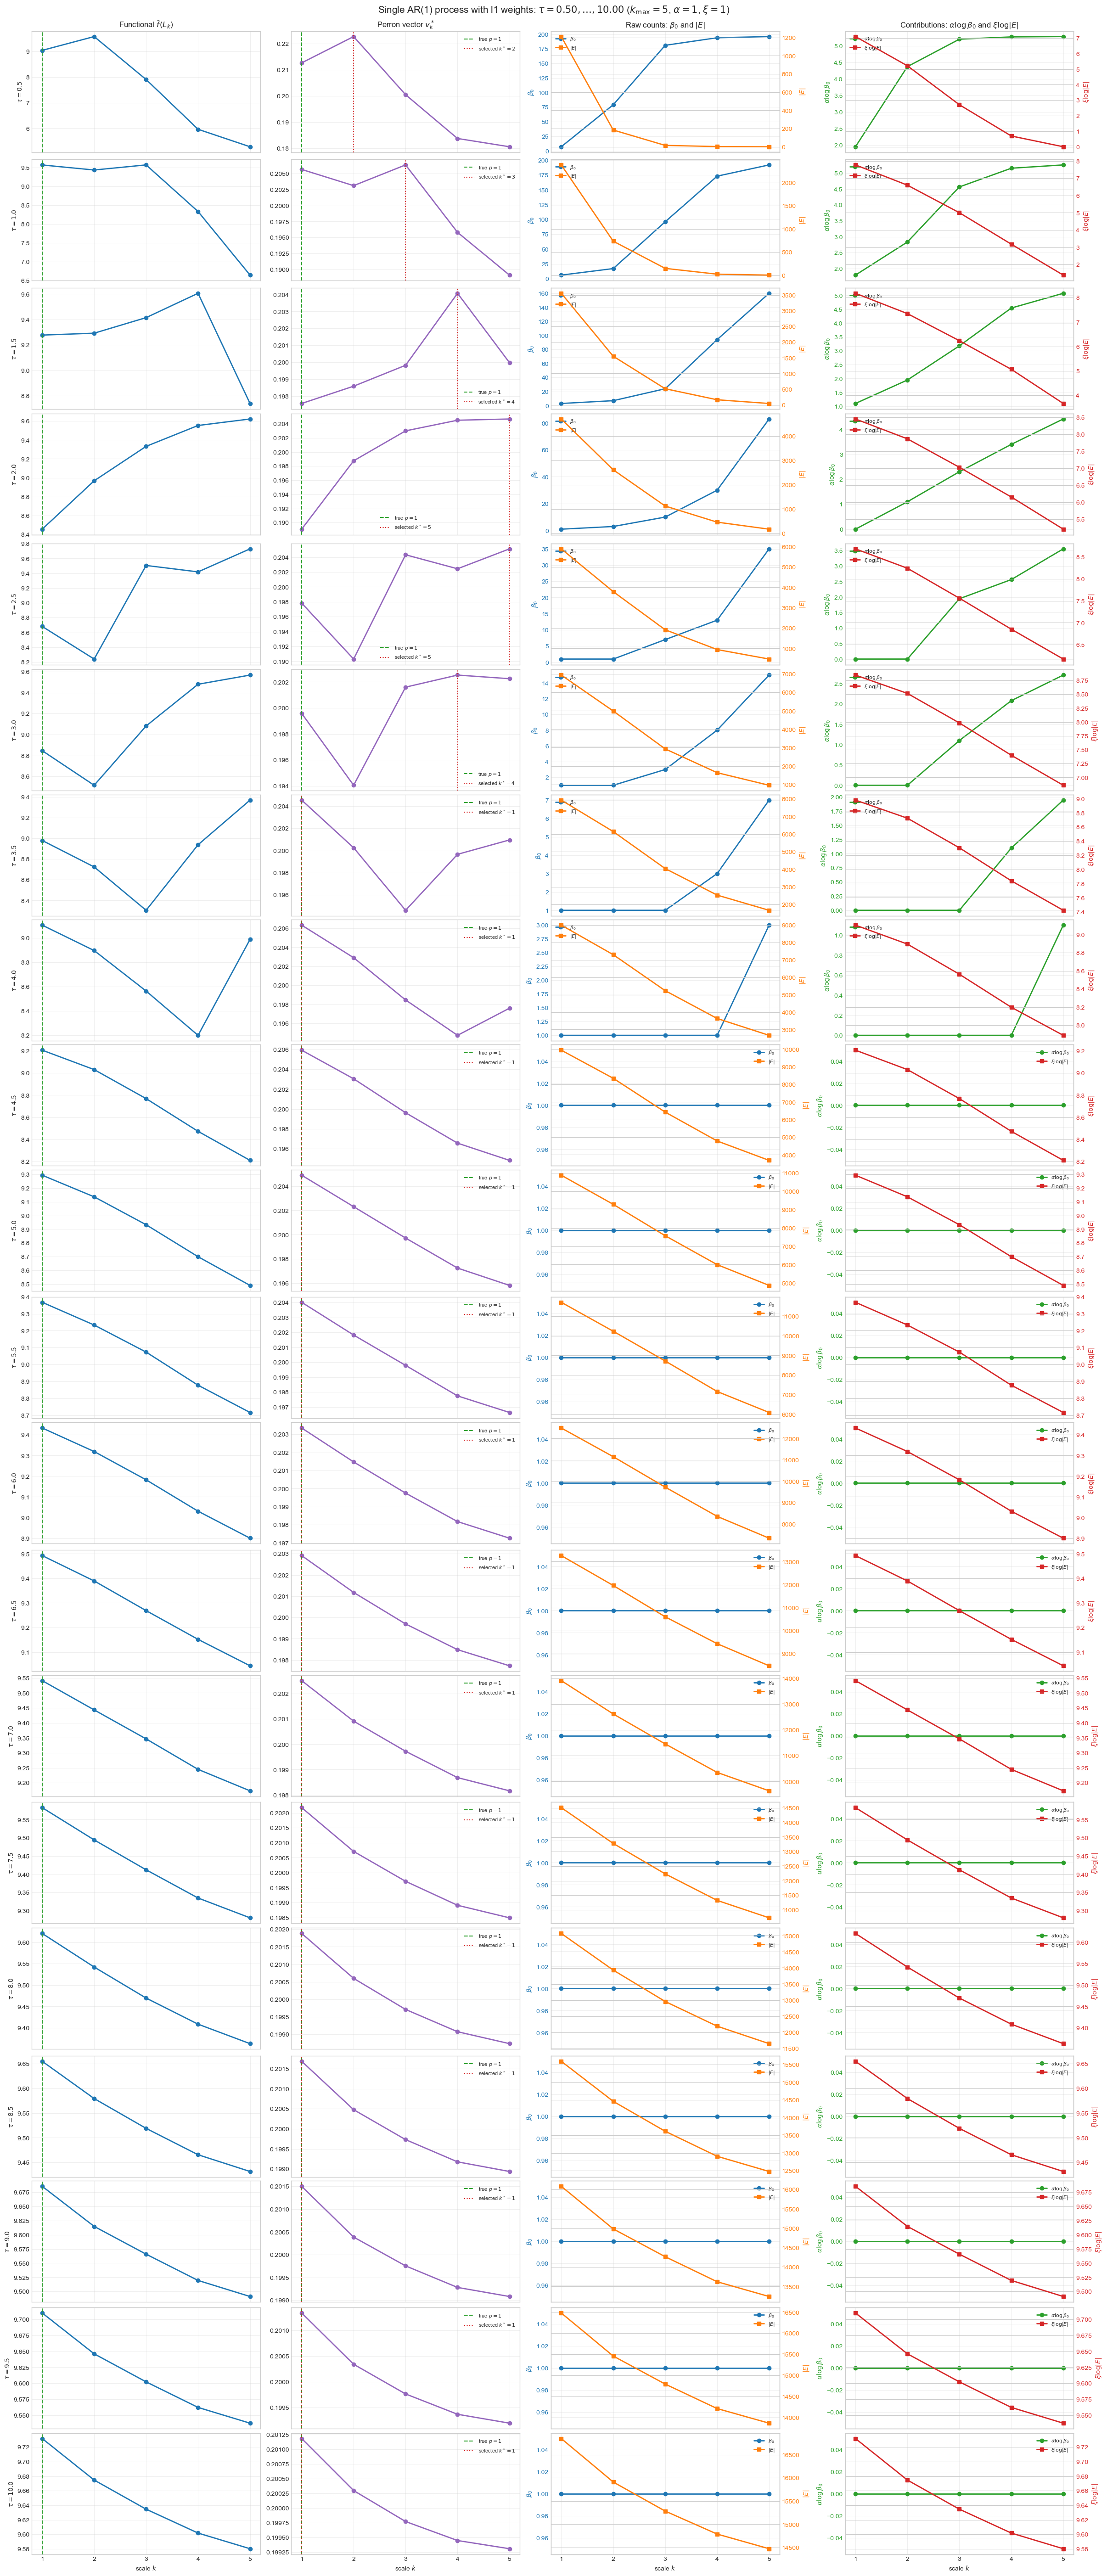

In [8]:
experiment_ks = np.arange(1, CONFIG.k_max + 1)
number_of_tau_values = len(experiment_tau_values)

fig, axes = plt.subplots(
    number_of_tau_values,
    4,
    figsize=(24, 2.8 * number_of_tau_values),
    sharex=True,
    constrained_layout=True,
)
axes = np.atleast_2d(axes)

for row, tau_value in enumerate(experiment_tau_values):
    curve = experiment_curves[float(tau_value)]
    functional_axis, perron_axis, counts_axis, contributions_axis = axes[row]

    functional_axis.plot(
        experiment_ks,
        curve["functional"],
        marker="o",
        linewidth=2,
        color="tab:blue",
    )
    functional_axis.axvline(1, color="tab:green", linestyle="--", label="true $p=1$")
    functional_axis.set_ylabel(rf"$\tau={tau_value:.1f}$")
    functional_axis.grid(alpha=0.3)

    perron_axis.plot(
        experiment_ks,
        curve["perron"],
        marker="o",
        linewidth=2,
        color="tab:purple",
    )
    perron_axis.axvline(1, color="tab:green", linestyle="--", label="true $p=1$")
    perron_axis.axvline(
        curve["k_star"],
        color="tab:red",
        linestyle=":",
        label=rf"selected $k^*={curve['k_star']}$",
    )
    perron_axis.grid(alpha=0.3)
    perron_axis.legend(loc="best", fontsize=8)

    beta_line = counts_axis.plot(
        experiment_ks,
        curve["beta_0"],
        marker="o",
        linewidth=2,
        color="tab:blue",
        label=r"$\beta_0$",
    )
    edges_axis = counts_axis.twinx()
    edge_line = edges_axis.plot(
        experiment_ks,
        curve["edges"],
        marker="s",
        linewidth=2,
        color="tab:orange",
        label=r"$|E|$",
    )
    counts_axis.set_ylabel(r"$\beta_0$", color="tab:blue")
    edges_axis.set_ylabel(r"$|E|$", color="tab:orange")
    counts_axis.tick_params(axis="y", colors="tab:blue")
    edges_axis.tick_params(axis="y", colors="tab:orange")
    counts_axis.grid(alpha=0.3)
    counts_axis.legend(beta_line + edge_line, [line.get_label() for line in beta_line + edge_line], loc="best", fontsize=8)

    beta_part_line = contributions_axis.plot(
        experiment_ks,
        curve["beta_contribution"],
        marker="o",
        linewidth=2,
        color="tab:green",
        label=r"$\alpha\log\beta_0$",
    )
    edge_part_axis = contributions_axis.twinx()
    edge_part_line = edge_part_axis.plot(
        experiment_ks,
        curve["edge_contribution"],
        marker="s",
        linewidth=2,
        color="tab:red",
        label=r"$\xi\log|E|$",
    )
    contributions_axis.set_ylabel(r"$\alpha\log\beta_0$", color="tab:green")
    edge_part_axis.set_ylabel(r"$\xi\log|E|$", color="tab:red")
    contributions_axis.tick_params(axis="y", colors="tab:green")
    edge_part_axis.tick_params(axis="y", colors="tab:red")
    contributions_axis.grid(alpha=0.3)
    contributions_axis.legend(
        beta_part_line + edge_part_line,
        [line.get_label() for line in beta_part_line + edge_part_line],
        loc="best",
        fontsize=8,
    )

axes[0, 0].set_title(r"Functional $\widetilde f(L_k)$")
axes[0, 1].set_title(r"Perron vector $v_k^*$")
axes[0, 2].set_title(r"Raw counts: $\beta_0$ and $|E|$")
axes[0, 3].set_title(r"Contributions: $\alpha\log\beta_0$ and $\xi\log|E|$")
for column in range(4):
    axes[-1, column].set_xlabel("scale $k$")
for axis in axes.flat:
    axis.set_xticks(experiment_ks)

fig.suptitle(
    rf"Single AR(1) process with {CONFIG.weight_type} weights: "
    rf"$\tau={experiment_tau_values[0]:.2f},\ldots,{experiment_tau_values[-1]:.2f}$ "
    rf"($k_{{\max}}={CONFIG.k_max}$, $\alpha={CONFIG.alpha:g}$, $\xi={CONFIG.xi:g}$)",
    fontsize=15,
)
plt.show()